# Showz: análisis de métricas de marketing (LTV, CAC, ROMI)

**Autora:** Daniela Salazar Canabal · Proyecto aprobado del bootcamp de Data Analytics de TripleTen

**Contexto:** Showz, una plataforma de venta de entradas para eventos, necesitaba optimizar su presupuesto de marketing. Analicé visitas, pedidos y costos de [período] para identificar qué fuentes de adquisición son rentables.

**Contenido:**
1. Comportamiento de usuarios: DAU/WAU/MAU, sesiones, retención
2. Ventas: conversión, ticket promedio, LTV por cohortes
3. Marketing: gasto, CAC y ROMI por fuente

**Resultado principal:** solo 3 de 7 fuentes son rentables. La fuente 3 consume el 42.9% del presupuesto pero recupera apenas $0.31 por cada dólar invertido (ROMI 0.31).


## Paso 1. Carga y preparación de datos

### Tabla `visits` — Registros de visitas al sitio web
- `Device`: dispositivo del usuario (móvil o escritorio)
- `End Ts`: fecha y hora de fin de la sesión
- `Source Id`: identificador de la fuente de anuncios
- `Start Ts`: fecha y hora de inicio de la sesión
- `Uid`: identificador único del usuario

### Tabla `orders` — Pedidos realizados
- `Buy Ts`: fecha y hora del pedido
- `Revenue`: ingreso generado por el pedido
- `Uid`: identificador único del usuario

### Tabla `costs` — Gastos de marketing
- `source_id`: identificador de la fuente de anuncios
- `dt`: fecha del gasto
- `costs`: monto gastado en esa fuente ese día


In [33]:
import pandas as pd 

#Cargar los datos
visits = pd.read_csv('/datasets/visits_log_us.csv')
orders = pd.read_csv('/datasets/orders_log_us.csv')
costs = pd.read_csv('/datasets/costs_us.csv')

## 1.1 Exploración inicial de los datos
Revisamos la estructura, tipos de datos y valores nulos. 

In [34]:
print('=== VISITS ===')
print(visits.head())
print(visits.info())

print('=== ORDERS ===')
print(orders.head())
print(orders.info())

print('=== COSTS ===')
print(costs.head())
print(costs.info())

=== VISITS ===
    Device               End Ts  Source Id             Start Ts  \
0    touch  2017-12-20 17:38:00          4  2017-12-20 17:20:00   
1  desktop  2018-02-19 17:21:00          2  2018-02-19 16:53:00   
2    touch  2017-07-01 01:54:00          5  2017-07-01 01:54:00   
3  desktop  2018-05-20 11:23:00          9  2018-05-20 10:59:00   
4  desktop  2017-12-27 14:06:00          3  2017-12-27 14:06:00   

                    Uid  
0  16879256277535980062  
1    104060357244891740  
2   7459035603376831527  
3  16174680259334210214  
4   9969694820036681168  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Device     359400 non-null  object
 1   End Ts     359400 non-null  object
 2   Source Id  359400 non-null  int64 
 3   Start Ts   359400 non-null  object
 4   Uid        359400 non-null  uint64
dtypes: int64(1), object(3), uint64(

### Hallazgos de la exploracíón inicial
-**visits**: 359,400 registros, sin valores nulos. 
  Las columnas `Start Ts` y `End Ts` están en formato object → convertir a datetime.
  Los nombres de columnas tienen mayúsculas y espacios → renombrar.
- **orders**: 50,415 registros, sin valores nulos.
  La columna `Buy Ts` está en formato object → convertir a datetime.
- **costs**: 2,542 registros, sin valores nulos.
  La columna `dt` está en formato object → convertir a datetime.

## 1.2 Limpieza y preparación de datos

A partir de la exploración inicial identificamos los siguientes cambios necesarios:

- **Renombrar columnas**: las columnas de `visits` y `orders` tienen 
  mayúsculas y espacios, las normalizaremos a minúsculas y sin espacios 
  para facilitar el trabajo.
- **Convertir fechas**: las columnas `Start Ts`, `End Ts` (visits), 
  `Buy Ts` (orders) y `dt` (costs) están en formato `object` y deben 
  convertirse a `datetime` para poder hacer cálculos de tiempo.
- **Verificar duplicados**: revisaremos si hay filas duplicadas en 
  cada tabla que deban eliminarse.
- **Verificar valores únicos**: revisaremos la variedad de valores 
  en columnas clave para entender mejor los datos.

In [35]:
#Renombrar columnas
visits.columns = ['device', 'end_ts', 'source_id', 'start_ts', 'uid']
orders.columns = ['buy_ts', 'revenue', 'uid']

#Convertir fechas a datetime
visits['start_ts'] = pd.to_datetime(visits['start_ts'])
visits['end_ts'] = pd.to_datetime(visits['end_ts'])
orders['buy_ts'] = pd.to_datetime(orders['buy_ts'])
costs['dt'] = pd.to_datetime(costs['dt'])

#Verificar duplicados
print('=== DUPLICADOS ===')
print('Duplicados en visits:', visits.duplicated().sum())
print('Duplicados en orders:', orders.duplicated().sum())
print('Duplicados en costs:', costs.duplicated().sum())

#Verificar valores unicos en columbas clave
print('\n=== VALORES ÚNICOS ===')
print('Usuarios únicos en visits:', visits['uid'].nunique())
print('Usuarios únicos en orders:', orders['uid'].nunique())
print('Dispositivos:', visits['device'].unique())
print('Fuentes de tráfico:', visits['source_id'].unique())
print('Fuentes en costs:', costs['source_id'].unique())

=== DUPLICADOS ===
Duplicados en visits: 0
Duplicados en orders: 0
Duplicados en costs: 0

=== VALORES ÚNICOS ===
Usuarios únicos en visits: 228169
Usuarios únicos en orders: 36523
Dispositivos: ['touch' 'desktop']
Fuentes de tráfico: [ 4  2  5  9  3  1 10  7  6]
Fuentes en costs: [ 1  2  3  4  5  9 10]


### Hallazgos de la limpieza: 
- Se renombraron las columnas a minúsculas y sin espacios.
- Se convirtieron las columnas de fecha al tipo datetime.
- **Sin duplicados** en ninguna de las tres tablas.

**Valores únicos encontrados:**
-**Usuarios únicos en visits:** 228,169 usuarios visitaron el sitio.
-**Usuarios únicos en orders:** 36,523 usuarios realizaron al menos una compra
 - Esto significa que solo el **16%** de los visitantes realizó una compra
-**Dispositivos:** dos tipos disponible `touch` (movil) y `desktop` (escritorio)
- **Fuentes de tráfico en visits**: 9 fuentes (1, 2, 3, 4, 5, 6, 7, 9, 10)
- **Fuentes de tráfico en costs**: 7 fuentes (1, 2, 3, 4, 5, 9, 10)
  - Las fuentes 6 y 7 aparecen en `visits` pero **no tienen datos de costos**,
    lo que puede indicar fuentes orgánicas o sin presupuesto asignado!!!

Los datos están listos para el análisis.

## Paso 2. Informes y métricas

En esta sección calcularemos las métricas clave divididas en tres áreas: 
1. **Visitas** - comportamiento de usuario en el sitio
2. **Ventas** - comportamiento de compra
3. **Marketing** - efectividad de la inversión

### 2.1 Análisis de Visitas

Responderemos las siguientes preguntas: 
- ¿Cuántas personas usan el sitio cada día, semana y mes? (DAU/WAU/MAU)
- ¿Cuántas sesiones hay por día?
- ¿Cual es la duración promedio de cada sesión? (ASL)
- ¿ Con qué frecuencia regresan los usuarios? (Sticky Factor)

### 2.1.1 Preparación de columnas de tiempo

Para poder agrupar las visitas por día, semana y mes, extraemos
estas unidades de tiempo de la columna `start_ts`.



In [36]:
#Agregar columnas de tiempo a visits
visits['date'] = visits['start_ts'].dt.date #2017-12-20
visits['year'] = visits['start_ts'].dt.year #2017
visits['month'] = visits['start_ts'].dt.month #2
visits['week'] = visits['start_ts'].dt.isocalendar().week.astype('int64') #51

# Verificar resultado
print(visits[['start_ts', 'date', 'year', 'month', 'week']].head(10))



             start_ts        date  year  month  week
0 2017-12-20 17:20:00  2017-12-20  2017     12    51
1 2018-02-19 16:53:00  2018-02-19  2018      2     8
2 2017-07-01 01:54:00  2017-07-01  2017      7    26
3 2018-05-20 10:59:00  2018-05-20  2018      5    20
4 2017-12-27 14:06:00  2017-12-27  2017     12    52
5 2017-09-03 21:35:00  2017-09-03  2017      9    35
6 2018-01-30 11:13:00  2018-01-30  2018      1     5
7 2017-11-05 15:14:00  2017-11-05  2017     11    44
8 2017-07-19 10:41:00  2017-07-19  2017      7    29
9 2017-11-08 13:42:00  2017-11-08  2017     11    45


### 2.1.2 Usuarios activos: DAU, WAU y MAU

Calculamos el número promedio de usuarios únicos por día, semana y mes
para entender el tamaño y crecimiento de la audiencia de Showz.

In [37]:

#DAU - usuarios únicos por día
dau = visits.groupby('date')['uid'].nunique()

#WAU - usuarios únicos por semana
wau = visits.groupby(['year', 'week'])['uid'].nunique()

#MAU - usuarios únicos por mes
mau = visits.groupby(['year', 'month'])['uid'].nunique()

#Calcular sticky factor
sticky_wau = dau.mean() / wau.mean() * 100
sticky_mau = dau.mean() / mau.mean() * 100

print('DAU promedio:', int(dau.mean()))
print('WAU promedio:', int(wau.mean()))
print('MAU promedio:', int(mau.mean()))
print()
print('Sticky Factor DAU/WAU:', round(sticky_wau, 2), '%')
print('Sticky Factor DAU/MAU:', round(sticky_mau, 2), '%')


DAU promedio: 907
WAU promedio: 5716
MAU promedio: 23228

Sticky Factor DAU/WAU: 15.88 %
Sticky Factor DAU/MAU: 3.91 %


### Hallazgos: Usuarios activos y Sticky Factor

| Métrica | Resultado |
|---------|-----------|
| DAU (diario) | 907 usuarios |
| WAU (semanal) | 5,716 usuarios |
| MAU (mensual) | 23,228 usuarios |
| Sticky Factor DAU/WAU | 15.88% |
| Sticky Factor DAU/MAU | 3.91% |

**Conclusiones:**
- En promedio, Showz recibe **907 usuarios únicos por día** y 
  **23,228 por mes**.
- El Sticky Factor DAU/WAU de **15.88%** indica que de cada 100 
  usuarios semanales, aproximadamente 16 regresan cada día.
- El Sticky Factor DAU/MAU de **3.91%** indica que de cada 100 
  usuarios mensuales, solo 4 visitan el sitio diariamente.
- Estos valores son **normales para una plataforma de venta de 
  entradas**, ya que los usuarios no necesitan visitar el sitio 
  todos los días, sino solo cuando buscan o compran entradas 
  para eventos específicos.

### 2.1.3 Sesiones por día 

Calculamos el número promedio de sesiones diarias. 
Un usuario puede tener más de una sesión por día. 

In [38]:
#Sesiones por día (cada fíla en visits es una sesión)
sessions_per_day = visits.groupby('date')['uid'].count()

print('Sesiones por día promedio:', int(sessions_per_day.mean()))
print('Sesiones totales:', len(visits))
print('Usuarios únicos totales:', visits['uid'].nunique())
print('Sesiones promedio por usuario:', 
      round(len(visits) / visits['uid'].nunique(), 2))

Sesiones por día promedio: 987
Sesiones totales: 359400
Usuarios únicos totales: 228169
Sesiones promedio por usuario: 1.58


### Hallazgos: Sesiones por día

| Métrica | Resultado |
|---------|-----------|
| Sesiones por día promedio | 987 |
| Sesiones totales | 359,400 |
| Usuarios únicos totales | 228,169 |
| Sesiones promedio por usuario | 1.58 |

**Conclusiones:**
- El promedio de 987 sesiones por día es ligeramente mayor al 
  DAU de 907, lo que confirma que algunos usuarios tienen 
  más de una sesión por día.
- En promedio, cada usuario tiene 1.58 sesiones a lo largo 
  del período analizado, lo que indica que la mayoría de los 
  usuarios visita el sitio pocas veces.
- Esto es consistente con el comportamiento esperado de una 
  plataforma de venta de entradas: los usuarios entran, 
  buscan entradas y se van.

### 2.1.4 Duración promedio de sesión (ASL)

Calculamos cuánto tiempo pasan los usuarios en el sitio por sesión.
Primero revisamos la distribución para determinar qué medida 
estadística es más apropiada: media, mediana o moda.

Media: 10.73 minutos
Mediana: 5.0 minutos
Moda: 1.0 minutos


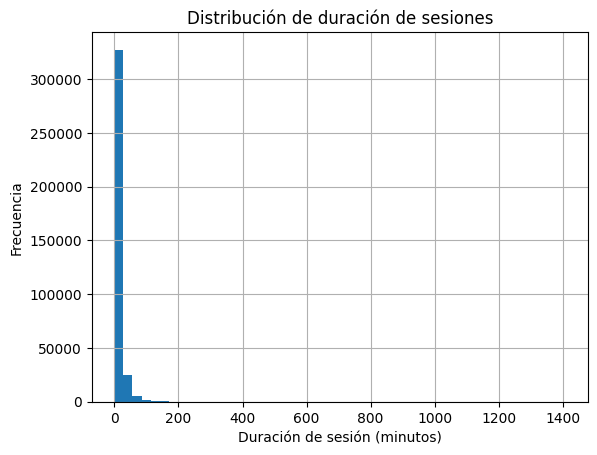

In [39]:
import matplotlib.pyplot as plt

# Calcular duración de sesión en minutos
visits['session_duration'] = (
    visits['end_ts'] - visits['start_ts']
).dt.seconds / 60

# Estadísticas básicas
print('Media:', round(visits['session_duration'].mean(), 2), 'minutos')
print('Mediana:', round(visits['session_duration'].median(), 2), 'minutos')
print('Moda:', round(visits['session_duration'].mode()[0], 2), 'minutos')

# Histograma para ver la distribución
visits['session_duration'].hist(bins=50)
plt.xlabel('Duración de sesión (minutos)')
plt.ylabel('Frecuencia')
plt.title('Distribución de duración de sesiones')
plt.show()

### Hallazgos: Duración promedio de sesión (ASL)

| Métrica | Resultado |
|---------|-----------|
| Media | 10.73 minutos |
| Mediana | 5.0 minutos |
| Moda | 1.0 minutos |

**Sobre la distribución:**
- El histograma muestra una distribución fuertemente sesgada 
  a la derecha: la gran mayoría de sesiones son muy cortas y 
  hay pocas sesiones muy largas que inflan la media.
- En este caso la mediana (5 minutos)es la medida más 
  representativa, ya que no se ve afectada por los valores 
  extremos como sí lo está la media.

**Conclusiones:**
- La mayoría de usuarios pasan aproximadamente 5 minutos 
  en el sitio por sesión.
- La moda de 1 minuto sugiere que muchos usuarios entran, 
  no encuentran lo que buscan y se van rápidamente.
- Esto podría indicar una oportunidad de mejora en la 
  experiencia del usuario para aumentar el tiempo de 
  permanencia y las conversiones.

### 2.1.5 Frecuencia de retorno de usuarios

Analizamos con qué frecuencia los usuarios regresan al sitio.
Para esto calculamos el número de sesiones por usuario y 
vemos cuántos usuarios regresan más de una vez.

Sesiones por usuario:
count    228169.000000
mean          1.575148
std           4.646800
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         893.000000
Name: n_sessions, dtype: float64

Usuarios que regresan (>1 sesión): 52128 (22.85%)


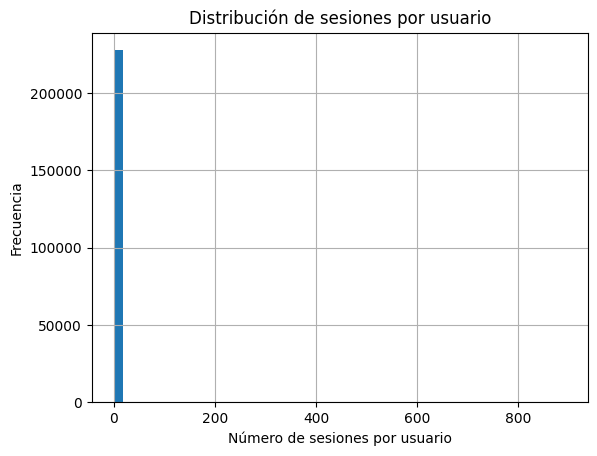

In [40]:
# Número de sesiones por usuario
sessions_by_user = visits.groupby('uid')['date'].count().reset_index()
sessions_by_user.columns = ['uid', 'n_sessions']

# Distribución de sesiones por usuario
print('Sesiones por usuario:')
print(sessions_by_user['n_sessions'].describe())
print()

# ¿Cuántos usuarios regresan más de una vez?
returning = sessions_by_user[sessions_by_user['n_sessions'] > 1]
print('Usuarios que regresan (>1 sesión):',
      len(returning),
      f'({round(len(returning) / len(sessions_by_user) * 100, 2)}%)')

# Visualización
sessions_by_user['n_sessions'].hist(bins=50)
plt.xlabel('Número de sesiones por usuario')
plt.ylabel('Frecuencia')
plt.title('Distribución de sesiones por usuario')
plt.show()

### Hallazgos: Frecuencia de retorno de usuarios

| Métrica | Resultado |
|---------|-----------|
| Promedio de sesiones por usuario | 1.58 |
| Mediana de sesiones por usuario | 1.0 |
| Máximo de sesiones por usuario | 893 |
| Usuarios que regresan (>1 sesión) | 52,128 (22.85%) |

**Sobre la distribución:**
- El histograma muestra que la gran mayoría de usuarios 
  tiene solo 1 sesión, lo que se confirma con la mediana de 1.
- El máximo de 893 sesiones por un solo usuario sugiere 
  la presencia de usuarios muy activos o posibles bots.

**Conclusiones:**
- Solo el 22.85% de los usuarios regresa al sitio más 
  de una vez, lo que indica una baja tasa de retorno.
- Esto representa una oportunidad de mejora: implementar 
  estrategias de retención como emails recordatorios, 
  notificaciones de eventos o programas de fidelización.

## 2.2 Análisis de Ventas

Analizamos el comportamiento de compra de los usuarios.
Responderemos las siguientes preguntas:
- ¿Cuándo hacen su primera compra después de registrarse?
- ¿Cuántos pedidos hacen por período?
- ¿Cuál es el tamaño promedio de compra?
- ¿Cuánto dinero traen? (LTV)

### 2.2.1 Preparación de columnas de tiempo para orders

In [41]:
# Extraer columnas de tiempo de orders
orders['date']  = orders['buy_ts'].dt.date
orders['year']  = orders['buy_ts'].dt.year
orders['month'] = orders['buy_ts'].dt.month
orders['week']  = orders['buy_ts'].dt.isocalendar().week.astype('int64')

# Verificar resultado
print(orders[['buy_ts', 'date', 'year', 'month', 'week']].head())
print('\nRango de fechas:')
print('Primera compra:', orders['buy_ts'].min())
print('Última compra:', orders['buy_ts'].max())

               buy_ts        date  year  month  week
0 2017-06-01 00:10:00  2017-06-01  2017      6    22
1 2017-06-01 00:25:00  2017-06-01  2017      6    22
2 2017-06-01 00:27:00  2017-06-01  2017      6    22
3 2017-06-01 00:29:00  2017-06-01  2017      6    22
4 2017-06-01 07:58:00  2017-06-01  2017      6    22

Rango de fechas:
Primera compra: 2017-06-01 00:10:00
Última compra: 2018-06-01 00:02:00


### Hallazgos: Preparación de datos de ventas

- Rango de fechas de compras: junio 2017 — junio 2018
- El rango de órdenes es menor que el de visitas 
  (visitas llegan hasta diciembre 2018), lo que significa 
  que contamps con más datos de visitas que de compras.

### 2.2.2 Tiempo hasta la primera compra

Analizamos cuánto tiempo pasa entre la primera visita 
de un usuario y su primera compra. Esto nos ayuda a 
entender qué tan rápido convierten los usuarios.

In [42]:
# Primera visita por usuario
first_visit = visits.groupby('uid')['start_ts'].min().reset_index()
first_visit.columns = ['uid', 'first_visit_ts']

# Primera compra por usuario
first_order = orders.groupby('uid')['buy_ts'].min().reset_index()
first_order.columns = ['uid', 'first_order_ts']

# Unir primera visita con primera compra
conversion = pd.merge(first_visit, first_order, on='uid')

# Calcular tiempo hasta primera compra en días
conversion['days_to_convert'] = (
    conversion['first_order_ts'] - conversion['first_visit_ts']
).dt.days

print('Tiempo hasta primera compra (días):')
print(conversion['days_to_convert'].describe())
print()
print('Conversión el mismo día (0 días):', 
      (conversion['days_to_convert'] == 0).sum(),
      f'({round((conversion["days_to_convert"] == 0).sum() / len(conversion) * 100, 2)}%)')

Tiempo hasta primera compra (días):
count    36523.000000
mean        16.729869
std         46.959088
min          0.000000
25%          0.000000
50%          0.000000
75%          2.000000
max        363.000000
Name: days_to_convert, dtype: float64

Conversión el mismo día (0 días): 26363 (72.18%)


### Hallazgos: Tiempo hasta la primera compra

| Métrica | Resultado |
|---------|-----------|
| Usuarios que compraron | 36,523 |
| Tiempo promedio hasta compra | 16.73 días |
| Mediana | 0 días |
| Máximo | 363 días |
| Conversión el mismo día | 26,363 (72.18%) |

**Conclusiones:**
- El 72.18% de los usuarios compra el mismo día de su 
  primera visita, lo que indica una alta intención de compra 
  al llegar al sitio.
- La mediana de 0 días confirma que la mayoría convierte 
  inmediatamente.
- La media de 16.73 días está inflada por usuarios que 
  tardan mucho en convertir (hasta 363 días).
- El 75% de los usuarios convierte en máximo 2 días, 
  lo que sugiere que si un usuario no compra en los primeros 
  días, es poco probable que lo haga pronto.

**Recomendación:**
- Enfocar estrategias de remarketing en los primeros 2 días 
  después de la primera visita, ya que es la ventana más 
  efectiva para convertir usuarios.

### 2.2.3 Pedidos por período

Analizamos cuántos pedidos se realizan por mes para 
entender el volumen de ventas a lo largo del tiempo.

Pedidos por mes:
    year  month  n_orders
0   2017      6      2354
1   2017      7      2363
2   2017      8      1807
3   2017      9      3387
4   2017     10      5679
5   2017     11      5659
6   2017     12      6218
7   2018      1      4721
8   2018      2      5281
9   2018      3      5326
10  2018      4      3273
11  2018      5      4346
12  2018      6         1

Promedio de pedidos por mes: 3878
Máximo de pedidos en un mes: 6218
Mínimo de pedidos en un mes: 1


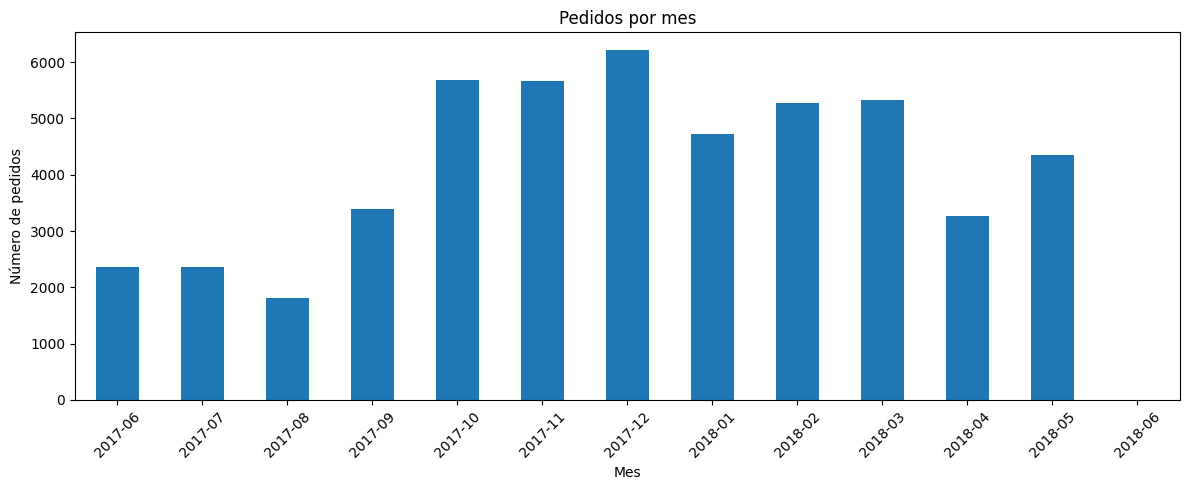

In [43]:
# Pedidos por mes
orders_per_month = orders.groupby(
    ['year', 'month']
)['uid'].count().reset_index()
orders_per_month.columns = ['year', 'month', 'n_orders']

print('Pedidos por mes:')
print(orders_per_month)
print()
print('Promedio de pedidos por mes:', 
      int(orders_per_month['n_orders'].mean()))
print('Máximo de pedidos en un mes:', 
      orders_per_month['n_orders'].max())
print('Mínimo de pedidos en un mes:', 
      orders_per_month['n_orders'].min())

# Visualización
orders_per_month['n_orders'].plot(
    kind='bar',
    figsize=(12, 5),
    title='Pedidos por mes'
)
plt.xlabel('Mes')
plt.ylabel('Número de pedidos')
plt.xticks(
    range(len(orders_per_month)),
    [f"{row['year']}-{row['month']:02d}" 
     for _, row in orders_per_month.iterrows()],
    rotation=45
)
plt.tight_layout()
plt.show()

### Hallazgos: Pedidos por período

| Métrica | Resultado |
|---------|-----------|
| Promedio de pedidos por mes | 3,878 |
| Máximo de pedidos en un mes | 6,218 (dic 2017) |
| Mínimo de pedidos en un mes | 1 (jun 2018) |

**Conclusiones:**
- Se observa un claro patrón estacional:
  - Agosto 2017 tiene una caída notable (1,807 pedidos)
  - Octubre - Diciembre 2017 muestra el pico más alto, 
    probablemente por la temporada de eventos de fin de año
  - Enero 2018 tiene una caída post-temporada navideña
  - Febrero - Marzo 2018 se recupera
  - Abril 2018 cae nuevamente
- Junio 2018 tiene solo 1 pedido, lo que indica 
  que los datos de ese mes están incompletos y no debe 
  considerarse en el análisis.
- La estacionalidad sugiere que Showz debería aumentar 
  el presupuesto de marketing en los meses previos a los 
  picos (septiembre-noviembre) para maximizar las ventas.

### 2.2.4 Tamaño promedio de compra

Analizamos cuánto gasta en promedio cada usuario 
por pedido (ticket promedio).

Estadísticas de ingresos por pedido:
count    50415.000000
mean         4.999647
std         21.818359
min          0.000000
25%          1.220000
50%          2.500000
75%          4.890000
max       2633.280000
Name: revenue, dtype: float64

Ticket promedio: 5.0
Mediana: 2.5


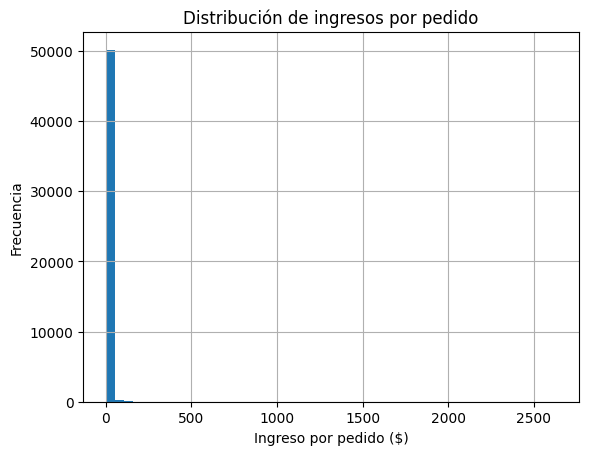

In [44]:
# Estadísticas de revenue
print('Estadísticas de ingresos por pedido:')
print(orders['revenue'].describe())
print()
print('Ticket promedio:', round(orders['revenue'].mean(), 2))
print('Mediana:', round(orders['revenue'].median(), 2))

# Visualización
orders['revenue'].hist(bins=50)
plt.xlabel('Ingreso por pedido ($)')
plt.ylabel('Frecuencia')
plt.title('Distribución de ingresos por pedido')
plt.show()

### Hallazgos: Tamaño promedio de compra

| Métrica | Resultado |
|---------|-----------|
| Ticket promedio (media) | \$5.00 |
| Mediana | \$2.50 |
| Mínimo | \$0.00 |
| Máximo | \$2,633.28 |
| 75% de pedidos | menos de \$4.89 |

**Sobre la distribución:**
- El histograma muestra una distribución fuertemente sesgada 
  a la derecha: la gran mayoría de pedidos son de montos 
  muy pequeños con algunos pedidos muy grandes.
- La mediana de USD 2.50 es más representativa que la media 
  de USD 5.00, ya que la media está inflada por pedidos 
  excepcionalmente grandes (hasta \$2,633).
- El 75% de los pedidos es de menos de \$4.89, lo que 
  indica que Showz maneja principalmente entradas de 
  bajo costo.

**Conclusiones:**
- Existen pedidos de \$0.00 que podrían ser entradas 
  gratuitas o errores en los datos.
- Los pedidos muy grandes (>\$500) son outliers que 
  podrían corresponder a compras corporativas o paquetes 
  especiales.
- El bajo ticket promedio sugiere que el volumen de 
  ventas es más importante que el valor unitario para 
  la rentabilidad de Showz.

### 2.2.5 LTV (Lifetime Value)

Calculamos cuánto dinero aporta cada cliente a Showz 
a lo largo del tiempo, agrupando por cohortes mensuales.

In [45]:
import numpy as np
# Primera compra por usuario (cohorte)
first_order_month = orders.groupby('uid')['buy_ts'].min().reset_index()
first_order_month.columns = ['uid', 'first_order_ts']
first_order_month['first_order_month'] = first_order_month[
    'first_order_ts'
].astype('datetime64[M]')

# Número de usuarios por cohorte
cohort_sizes = first_order_month.groupby(
    'first_order_month'
)['uid'].nunique().reset_index()
cohort_sizes.columns = ['first_order_month', 'n_buyers']

# Agregar mes de cohorte a orders
orders['order_month'] = orders['buy_ts'].astype('datetime64[M]')
orders_ = pd.merge(orders, first_order_month[['uid', 'first_order_month']], on='uid')

# Agrupar por cohorte y mes de compra
cohorts = orders_.groupby(
    ['first_order_month', 'order_month']
).agg({'revenue': 'sum'}).reset_index()

# Unir con cohort_sizes
report = pd.merge(cohort_sizes, cohorts, on='first_order_month')

# Calcular LTV
report['ltv'] = report['revenue'] / report['n_buyers']

# Tabla dinámica de LTV
report['age'] = (
    report['order_month'] - report['first_order_month']
) / np.timedelta64(1, 'M')
report['age'] = report['age'].round().astype('int')

ltv_pivot = report.pivot_table(
    index='first_order_month',
    columns='age',
    values='ltv',
    aggfunc='mean'
).round(2)

print(ltv_pivot.fillna(''))

age                  0     1     2     3     4     5     6     7     8     9   \
first_order_month                                                               
2017-06-01         4.72  0.49  0.44  0.95  1.02  0.74  0.95  0.58  0.55  0.61   
2017-07-01         6.01  0.34  0.62  0.36  0.18  0.16  0.12  0.14  0.16  0.15   
2017-08-01         5.28  0.47  0.46  0.39  0.49  0.28  0.21  0.41  0.29  0.19   
2017-09-01         5.64  1.12  0.52  3.98   0.4  0.65   0.7  0.24  0.18         
2017-10-01         5.00  0.54  0.19  0.16  0.15  0.12  0.08  0.12               
2017-11-01         5.15   0.4   0.2  0.32  0.15  0.05  0.11                     
2017-12-01         4.74  0.26  0.93  1.07  0.31  0.34                           
2018-01-01         4.14  0.29   0.3  0.14  0.06                                 
2018-02-01         4.16  0.28  0.08  0.07                                       
2018-03-01         4.84   0.3  0.32                                             
2018-04-01         4.66  0.5

### Hallazgos: LTV por cohorte

| Cohorte | LTV mes 0 | LTV acumulado |
|---------|-----------|---------------|
| Jun 2017 | \$4.72 | Mayor (12 meses de datos) |
| Jul 2017 | \$6.01 | Alto mes 0 |
| Ago 2017 | \$5.28 | Promedio |
| Sep 2017 | \$5.64 | Pico en mes 3 ($3.98) |
| May 2018 | \$4.66 | Solo mes 0 |
| Jun 2018 | \$3.42 | Solo mes 0 (datos incompletos) |

**Conclusiones:**
- El LTV más alto en el mes 0 corresponde a julio 2017 
  (\$6.01), lo que indica que esa cohorte hizo compras más 
  grandes en su primer mes.
- Después del mes 0, el LTV cae drásticamente en todos 
  los casos, lo que confirma que la mayoría de usuarios 
  compra principalmente en su primer mes.
- La cohorte de septiembre 2017 tiene un pico inusual 
  en el mes 3 (\$3.98), lo que podría indicar un evento 
  especial o campaña de marketing en diciembre 2017.
- La cohorte de junio 2017 tiene datos hasta el mes 11, 
  siendo la más madura y con el LTV acumulado más alto.
- Las cohortes más recientes tienen menos meses de datos, 
  por lo que su LTV acumulado será naturalmente menor.

## 2.3 Análisis de Marketing

Analizamos la efectividad de la inversión en marketing.
Responderemos las siguientes preguntas:
- ¿Cuánto dinero se gastó en total y por fuente?
- ¿Cuál fue el CAC de cada fuente?
- ¿Cuán rentables fueron las inversiones? (ROMI)

### 2.3.1 Gastos de marketing

Analizamos cuánto se gastó en total, por fuente 
y a lo largo del tiempo.

Gasto total en marketing: 329131.62

Gasto por fuente:
   source_id  total_costs
2          3    141321.63
3          4     61073.60
4          5     51757.10
1          2     42806.04
0          1     20833.27
6         10      5822.49
5          9      5517.49


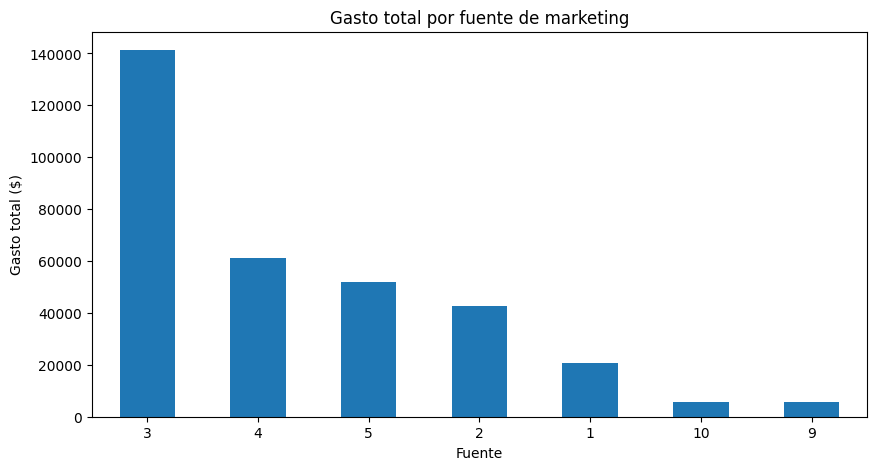

In [46]:
# Gasto total
print('Gasto total en marketing:', 
      round(costs['costs'].sum(), 2))

# Gasto por fuente
costs_by_source = costs.groupby('source_id')['costs'].sum().reset_index()
costs_by_source.columns = ['source_id', 'total_costs']
costs_by_source = costs_by_source.sort_values('total_costs', ascending=False)
print('\nGasto por fuente:')
print(costs_by_source)

# Visualización gasto por fuente
costs_by_source.plot(
    kind='bar',
    x='source_id',
    y='total_costs',
    figsize=(10, 5),
    title='Gasto total por fuente de marketing',
    legend=False
)
plt.xlabel('Fuente')
plt.ylabel('Gasto total ($)')
plt.xticks(rotation=0)
plt.show()

### Hallazgos: Gastos de marketing

| Fuente | Gasto total | % del total |
|--------|-------------|-------------|
| Fuente 3 | \$141,321.63 | 42.9% |
| Fuente 4 | \$61,073.60 | 18.6% |
| Fuente 5 | \$51,757.10 | 15.7% |
| Fuente 2 | \$42,806.04 | 13.0% |
| Fuente 1 | \$20,833.27 | 6.3% |
| Fuente 10 | \$5,822.49 | 1.8% |
| Fuente 9 | \$5,517.49 | 1.7% |
| **Total** | **\$329,131.62** | **100%** |

**Conclusiones:**
- La fuente 3 concentra el 42.9% del presupuesto total 
  de marketing, siendo con diferencia la más costosa.
- Las fuentes 9 y 10 tienen los gastos más bajos, 
  representando apenas el 3.5% del presupuesto total.
- Recordemos que las fuentes 6 y 7 aparecen en visits 
  pero no tienen costos registrados, por lo que no 
  aparecen aquí.
- El alto gasto en la fuente 3 no necesariamente significa 
  que sea la más rentable → lo veremos al calcular el CAC 
  y el ROMI.

### 2.3.2 CAC por fuente (Costo de Adquisición de Cliente)

Calculamos cuánto le costó a Showz adquirir cada cliente
por fuente de marketing. Para esto dividimos el gasto total
de cada fuente entre el número de nuevos clientes que trajo.

CAC por fuente:
   source_id  total_costs  n_buyers        cac
6          9      5517.49      1415   3.899286
5         10      5822.49      1241   4.691773
4          1     20833.27      3743   5.565928
1          4     61073.60      9823   6.217408
2          5     51757.10      6839   7.567934
3          2     42806.04      4323   9.901929
0          3    141321.63      9138  15.465269


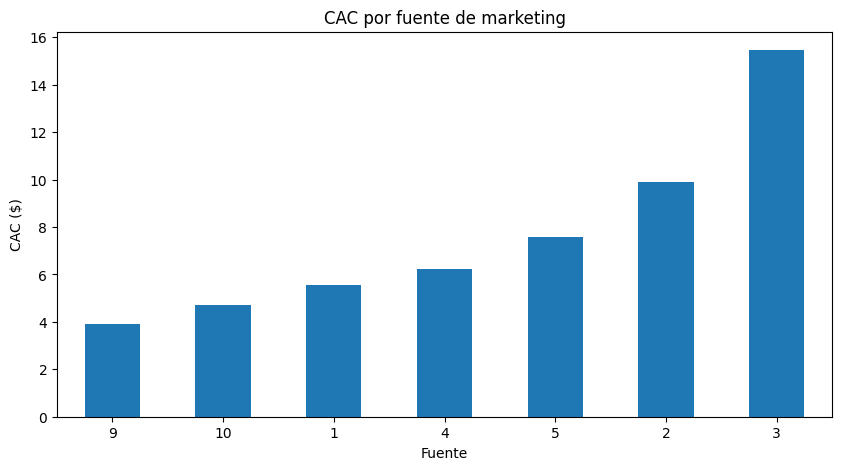

In [47]:
# Primera visita por usuario con su fuente
first_visit_source = visits.groupby('uid').agg(
    {'start_ts': 'min', 'source_id': 'first'}
).reset_index()
first_visit_source.columns = ['uid', 'first_visit_ts', 'source_id']

# Usuarios que compraron con su fuente
buyers_by_source = pd.merge(
    first_visit_source, 
    first_order_month[['uid']], 
    on='uid'
)

# Contar compradores por fuente
buyers_count = buyers_by_source.groupby(
    'source_id'
)['uid'].nunique().reset_index()
buyers_count.columns = ['source_id', 'n_buyers']

# Unir con costos por fuente
cac_by_source = pd.merge(costs_by_source, buyers_count, on='source_id')

# Calcular CAC
cac_by_source['cac'] = (
    cac_by_source['total_costs'] / cac_by_source['n_buyers']
)

print('CAC por fuente:')
print(cac_by_source.sort_values('cac'))

# Visualización
cac_by_source.sort_values('cac').plot(
    kind='bar',
    x='source_id',
    y='cac',
    figsize=(10, 5),
    title='CAC por fuente de marketing',
    legend=False
)
plt.xlabel('Fuente')
plt.ylabel('CAC ($)')
plt.xticks(rotation=0)
plt.show()

### Hallazgos: CAC por fuente de marketing

| Fuente | Gasto total | Compradores | CAC |
|--------|-------------|-------------|-----|
| Fuente 9 | \$5,517.49 | 1,415 | **\$3.90** |
| Fuente 10 | \$5,822.49 | 1,241 | **\$4.69** |
| Fuente 1 | \$20,833.27 | 3,743 | **\$5.57** |
| Fuente 4 | \$61,073.60 | 9,823 | **\$6.22** |
| Fuente 5 | \$51,757.10 | 6,839 | **\$7.57** |
| Fuente 2 | \$42,806.04 | 4,323 | **\$9.90** |
| Fuente 3 | \$141,321.63 | 9,138 | **\$15.47** |

**Conclusiones:**
- La **fuente 9** tiene el CAC más bajo (\$3.90), lo que 
  significa que es la más eficiente para adquirir clientes.
- La **fuente 3** tiene el CAC más alto (\$15.47) y además 
  es la que más presupuesto consume (42.9% del total).
- La **fuente 4** trae el mayor número de compradores (9,823) 
  a un CAC razonable (\$6.22).
- Un CAC bajo no necesariamente significa que la fuente 
  es la mejor → necesitamos calcular el ROMI para saber 
  si los clientes que trae generan suficientes ingresos.

### 2.3.3 ROMI por fuente (Retorno de Inversión en Marketing)

Calculamos el retorno de la inversión en marketing por fuente.
El ROMI nos dice si los ingresos generados por los clientes 
de cada fuente justifican el gasto en marketing.

ROMI = LTV / CAC
- ROMI > 1 → la inversión es rentable
- ROMI < 1 → la inversión no se recupera

ROMI por fuente:
   source_id    avg_ltv        cac      romi
4          1  10.301913   5.565928  1.850889
3          2  15.071076   9.901929  1.522034
6          9   5.001399   3.899286  1.282645
1          4   5.342538   6.217408  0.859287
2          5   5.901142   7.567934  0.779756
5         10   3.312925   4.691773  0.706114
0          3   4.849823  15.465269  0.313594


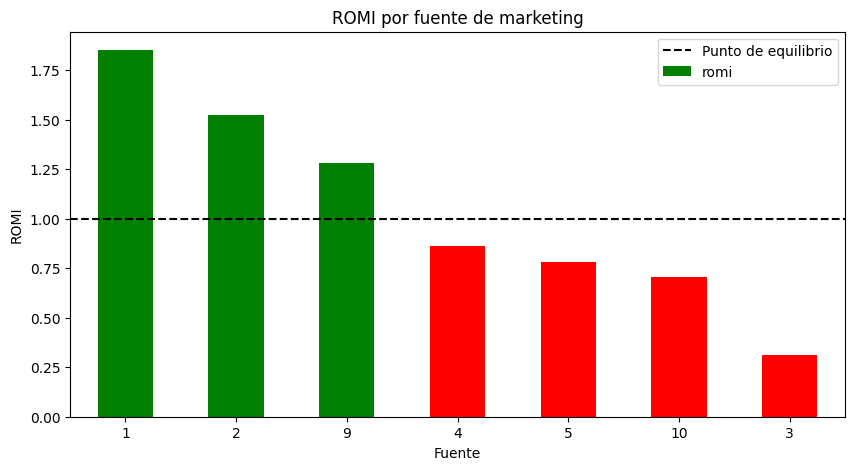

In [48]:
# LTV total por usuario
ltv_by_user = orders.groupby('uid')['revenue'].sum().reset_index()
ltv_by_user.columns = ['uid', 'ltv']

# Unir con fuente de cada usuario
ltv_by_source = pd.merge(
    first_visit_source[['uid', 'source_id']], 
    ltv_by_user, 
    on='uid'
)

# LTV promedio por fuente
ltv_avg_by_source = ltv_by_source.groupby(
    'source_id'
)['ltv'].mean().reset_index()
ltv_avg_by_source.columns = ['source_id', 'avg_ltv']

# Unir con CAC
romi_by_source = pd.merge(cac_by_source, ltv_avg_by_source, on='source_id')

# Calcular ROMI
romi_by_source['romi'] = (
    romi_by_source['avg_ltv'] / romi_by_source['cac']
)

print('ROMI por fuente:')
print(romi_by_source[['source_id', 'avg_ltv', 'cac', 'romi']].sort_values(
    'romi', ascending=False
))

# Visualización
romi_by_source.sort_values('romi', ascending=False).plot(
    kind='bar',
    x='source_id',
    y='romi',
    figsize=(10, 5),
    title='ROMI por fuente de marketing',
    legend=False,
    color=['green' if x > 1 else 'red' 
           for x in romi_by_source.sort_values(
               'romi', ascending=False
           )['romi']]
)
plt.axhline(y=1, color='black', linestyle='--', label='Punto de equilibrio')
plt.xlabel('Fuente')
plt.ylabel('ROMI')
plt.xticks(rotation=0)
plt.legend()
plt.show()

### Hallazgos: ROMI por fuente de marketing

| Fuente | LTV promedio | CAC | ROMI | ¿Rentable? |
|--------|-------------|-----|------|-----------|
| Fuente 1 | \$10.30 | \$5.57 | 1.85 | Sí |
| Fuente 2 | \$15.07 | \$9.90 | 1.52 | Sí |
| Fuente 9 | \$5.00 | \$3.90 | 1.28 | Sí |
| Fuente 4 | \$5.34 | \$6.22 | 0.86 | No |
| Fuente 5 | \$5.90 | \$7.57 | 0.78 | No |
| Fuente 10 | \$3.31 | \$4.69 | 0.71 | No |
| Fuente 3 | \$4.85 | \$15.47 | 0.31 | No |

**Conclusiones:**
- Solo 3 fuentes son rentables (ROMI > 1): fuentes 1, 2 y 9.
- La **fuente 1** tiene el mejor ROMI (1.85) — por cada dolar invertido, genera \$1.85 en ingresos.
- La **fuente 2** tiene el LTV más alto (\$15.07), lo que indica que atrae clientes que gastan más.
- La **fuente 3** es la más preocupante:
  - Consume el 42.9% del presupuesto total
  - Tiene el CAC más alto (\$15.47)
  - Tiene el ROMI más bajo (0.31)
  - Por cada dolar invertido, solo recupera \$0.31
- La **fuente 9** es eficiente: bajo CAC (\$3.90) y ROMI positivo (1.28) aunque con bajo presupuesto.



### 3.1 Resumen de hallazgos

#### Visitas:
- Showz recibe en promedio 907 usuarios únicos por día
  y 23,228 por mes.
- El 22.85% de los usuarios regresa más de una vez.
- La duración mediana de sesión es de 5 minutos.
- El Sticky Factor es bajo (15.88% WAU, 3.91% MAU), 
  lo cual es normal para una plataforma de venta de entradas.

#### Ventas:
- El 72.18% de los usuarios compra el mismo día 
  de su primera visita.
- El ticket promedio es de USD 5.00 (mediana \$2.50).
- Los meses de mayor venta son octubre-diciembre, 
  lo que indica estacionalidad en la demanda.
- El LTV más alto corresponde a la cohorte de julio 2017.

#### Marketing:
- El presupuesto total fue de \$329,131.62.
- Solo 3 de 7 fuentes son rentables: fuentes 1, 2 y 9.
- La **fuente 3** consume el 42.9% del presupuesto 
  pero tiene el ROMI más bajo (0.31).
- La **fuente 1** tiene el mejor ROMI (1.85).
- La **fuente 2** atrae los clientes con mayor LTV (\$15.07).

### 3.2 Recomendaciones para el equipo de marketing

#### Fuentes donde SE DEBE aumentar la inversión:

**Fuente 1 — Mayor ROMI (1.85):**
- Es la fuente más eficiente en términos de retorno.
- Por cada dolar invertido genera \$1.85.
- Recomendamos aumentar su presupuesto ya que 
  tiene margen para crecer.

**Fuente 2 — Mayor LTV (\$15.07):**
- Atrae clientes que gastan más a lo largo del tiempo.
- Con un ROMI de 1.52 es rentable y sostenible.
- Recomendamos mantener o aumentar la inversión.

**Fuente 9 — CAC más bajo (\$3.90):**
- Es la fuente más económica para adquirir clientes.
- Con un ROMI de 1.28 es rentable.
- Actualmente recibe muy poco presupuesto (\$5,517).
- Recomendamos aumentar significativamente su 
  presupuesto para escalar resultados.

#### Fuentes donde SE DEBE reducir la inversión:

**Fuente 3 — ROMI crítico (0.31):**
- Consume el 42.9% del presupuesto total (\$141,321).
- Por cada dolar invertido solo recupera \$0.31.
- Es la fuente menos eficiente por amplio margen.
- Recomendamos reducir drásticamente su presupuesto 
  y redirigirlo a las fuentes 1, 2 y 9.

**Fuentes 4, 5 y 10 — ROMI menor a 1:**
- Ninguna recupera la inversión (ROMI < 1).
- Recomendamos evaluar su continuidad y reducir 
  presupuesto hasta mejorar su rendimiento.

#### Recomendaciones estacionales:
- Aumentar el presupuesto de marketing en 
  septiembre-octubre para aprovechar el pico 
  de ventas de fin de año.
- Implementar campañas de remarketing en los primeros 
  2 días después de la primera visita, ya que el 
  72.18% de conversiones ocurre el mismo día.


